<a href="https://colab.research.google.com/github/edensabag10/Data_Mining_Project/blob/main/Unet_Algorithm_Data_Mining_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms
from torch.utils.data import DataLoader, random_split
import zipfile
with zipfile.ZipFile("/content/stage1_train.zip", "r") as zip_ref:
    zip_ref.extractall("/content")

In [ ]:
# Basic convolution block used throughout the U-Net.
# It extracts features from the image while keeping the spatial size unchanged.
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels, mid_channels=None):
        super().__init__()

        if mid_channels is None:
            mid_channels = out_channels

        self.double_conv = nn.Sequential(
            # Convolution learns visual features such as edges, shapes and textures
            nn.Conv2d(in_channels, mid_channels, kernel_size=3, padding=1, bias=False),

            # Stabilizes the training process
            nn.BatchNorm2d(mid_channels),

            nn.ReLU(inplace=True),

            # Second convolution learns more complex features
            nn.Conv2d(mid_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)


# Down block - Encoder part.
# This part reduces the image size and increases the number of feature channels.
# Its goal is to understand what appears in the image.
class Down(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.maxpool_conv = nn.Sequential(
            # Reduces height and width by 2
            nn.MaxPool2d(kernel_size=2),

            # Extracts deeper features after the reduction
            DoubleConv(in_channels, out_channels)
        )

    def forward(self, x):
        return self.maxpool_conv(x)


# Up block - Decoder part.
# This part increases the image size back toward the original resolution.
# It also combines decoder information with encoder information using skip connections.
class Up(nn.Module):
    def __init__(self, in_channels, out_channels, bilinear=True):
        super().__init__()

        if bilinear:
            # Upsamples the feature map by a factor of 2
            self.up = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=True)

            self.conv = DoubleConv(in_channels, out_channels, mid_channels=in_channels // 2)

        else:
            # Learnable upsampling method
            self.up = nn.ConvTranspose2d(
                in_channels,
                in_channels // 2,
                kernel_size=2,
                stride=2
            )

            self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x1, x2):
        # x1 comes from the decoder
        # x2 comes from the encoder through the skip connection

        x1 = self.up(x1)

        # Handles possible size differences between encoder and decoder feature maps
        diffY = x2.size()[2] - x1.size()[2]
        diffX = x2.size()[3] - x1.size()[3]

        x1 = F.pad(
            x1,
            [
                diffX // 2,
                diffX - diffX // 2,
                diffY // 2,
                diffY - diffY // 2
            ]
        )

        # Skip connection:
        # combines accurate spatial information from the encoder
        # with semantic information from the decoder
        x = torch.cat([x2, x1], dim=1)

        return self.conv(x)


# Final output layer.
# Converts the last feature map into the required number of output channels.
class OutConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        # 1x1 convolution changes the number of channels without changing image size
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=1)

    def forward(self, x):
        return self.conv(x)


# Complete U-Net model.
# The network has three main parts:
# 1. Encoder / Down path - extracts features and reduces image size
# 2. Bottleneck - the deepest representation of the image
# 3. Decoder / Up path - restores image size and produces pixel-level output
class UNet(nn.Module):
    def __init__(self, n_channels, n_classes, bilinear=False):
        super().__init__()

        self.n_channels = n_channels
        self.n_classes = n_classes
        self.bilinear = bilinear

        # Initial feature extraction
        self.inc = DoubleConv(n_channels, 64)

        # Encoder / Down path
        self.down1 = Down(64, 128)
        self.down2 = Down(128, 256)
        self.down3 = Down(256, 512)

        factor = 2 if bilinear else 1

        # Bottleneck - deepest part of the network
        self.down4 = Down(512, 1024 // factor)

        # Decoder / Up path
        self.up1 = Up(1024, 512 // factor, bilinear)
        self.up2 = Up(512, 256 // factor, bilinear)
        self.up3 = Up(256, 128 // factor, bilinear)
        self.up4 = Up(128, 64, bilinear)

        # Final layer that produces logits for each pixel
        self.outc = OutConv(64, n_classes)

    def forward(self, x):
        # Encoder outputs are saved for skip connections
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)

        # Bottleneck
        x5 = self.down4(x4)

        # Decoder uses skip connections from the encoder
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)

        # Raw output of the model: logits per pixel
        logits = self.outc(x)

        return logits

In [ ]:
class DSB2018Dataset(Dataset):
    def __init__(self, root_dir, image_size=256):
        self.root_dir = root_dir
        self.image_ids = []

        # Scan the dataset and keep only folders that contain both
        # an image and its corresponding masks.
        for folder in os.listdir(root_dir):
            folder_path = os.path.join(root_dir, folder)

            images_path = os.path.join(folder_path, "images")
            masks_path = os.path.join(folder_path, "masks")

            if os.path.isdir(folder_path) and os.path.exists(images_path) and os.path.exists(masks_path):
                self.image_ids.append(folder)

        print("Dataset size:", len(self.image_ids))

        # Resize all images to a fixed size and convert them to tensors.
        self.image_transform = transforms.Compose([
            transforms.Resize((image_size, image_size)),
            transforms.ToTensor()
        ])

        # Apply the same preprocessing to masks.
        self.mask_transform = transforms.Compose([
            transforms.Resize((image_size, image_size)),
            transforms.ToTensor()
        ])

    def __len__(self):
        # Returns the number of samples in the dataset.
        return len(self.image_ids)

    def __getitem__(self, idx):
        # Retrieve a specific sample by its index.
        image_id = self.image_ids[idx]

        # Each sample contains a single microscopy image.
        image_path = glob.glob(
            os.path.join(self.root_dir, image_id, "images", "*.png")
        )[0]

        # Each sample may contain multiple nucleus masks.
        mask_paths = glob.glob(
            os.path.join(self.root_dir, image_id, "masks", "*.png")
        )

        # Load the input image.
        image = Image.open(image_path).convert("RGB")

        # Create an empty mask that will store all nuclei together.
        full_mask = np.zeros(Image.open(mask_paths[0]).size[::-1], dtype=np.uint8)

        # Merge all nucleus masks into a single ground-truth mask.
        for mask_path in mask_paths:
            mask = Image.open(mask_path).convert("L")
            mask = np.array(mask)

            # Keep all pixels that belong to any nucleus.
            full_mask = np.maximum(full_mask, mask)

        full_mask = Image.fromarray(full_mask)

        # Convert image and mask to tensors and resize them.
        image = self.image_transform(image)
        mask = self.mask_transform(full_mask)

        # Convert the mask into a binary segmentation mask:
        # 1 = nucleus, 0 = background.
        mask = (mask > 0).float()

        # Return one training sample:
        # input image + ground-truth mask.
        return image, mask

In [ ]:
def calculate_metrics(outputs, masks, threshold=0.5):
    probs = torch.sigmoid(outputs)
    preds = (probs > threshold).float()

    correct = (preds == masks).float().sum()
    total = torch.numel(masks)
    pixel_accuracy = correct / total

    intersection = (preds * masks).sum()
    union = preds.sum() + masks.sum()

    dice = (2 * intersection + 1e-7) / (union + 1e-7)

    iou = (intersection + 1e-7) / (preds.sum() + masks.sum() - intersection + 1e-7)

    return pixel_accuracy.item(), dice.item(), iou.item()

In [ ]:
dataset = DSB2018Dataset("/content", image_size=256)
print(len(dataset))

Dataset size: 670
670


Image shape: torch.Size([3, 256, 256])
Mask shape: torch.Size([1, 256, 256])


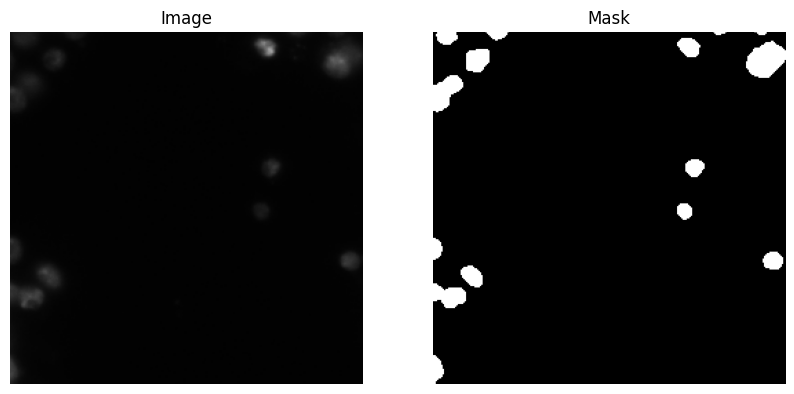

In [ ]:
image, mask = dataset[0]

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(image.permute(1,2,0))
plt.title("Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(mask.squeeze(), cmap="gray")
plt.title("Mask")
plt.axis("off")

plt.show()

In [ ]:
# Split the dataset into training set and test set
train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size

train_dataset, test_dataset = random_split(dataset,[train_size, test_size])

print("Train size:", len(train_dataset))
print("Test size:", len(test_dataset))

# DataLoader loads the data in small batches during training
train_loader = DataLoader(train_dataset,batch_size=4,shuffle=True)

test_loader = DataLoader(test_dataset,batch_size=4,shuffle=False)

Train size: 536
Test size: 134


In [ ]:
images, masks = next(iter(train_loader))

print("Images batch shape:", images.shape)
print("Masks batch shape:", masks.shape)

Images batch shape: torch.Size([4, 3, 256, 256])
Masks batch shape: torch.Size([4, 1, 256, 256])


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create the U-Net model.
# n_channels=3 because the input images are RGB.
# n_classes=1 because we want one output mask:
# 0 = background, 1 = nucleus.
model = UNet(n_channels=3, n_classes=1)
model = model.to(device)

# Loss function.
# Compares the predicted mask produced by the model
# with the true mask loaded from the dataset.
# Suitable for binary segmentation tasks.
criterion = nn.BCEWithLogitsLoss()

# Optimizer.
# Updates the network weights after each training step
# in order to reduce the loss.
# model.parameters() = all trainable weights of the U-Net.
# lr = learning rate (how large each update step is).
optimizer = torch.optim.Adam(model.parameters(),lr=1e-4)

In [ ]:
num_epochs = 7

for epoch in range(num_epochs):
    model.train()

    total_loss = 0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        # Forward pass:
        # send the images through the U-Net model
        outputs = model(images)

        # Calculate the loss:
        # compare predicted masks with true masks
        loss = criterion(outputs, masks)

        # Clear old gradients from the previous batch
        optimizer.zero_grad()

        # Backpropagation:
        # calculate how each weight contributed to the loss
        loss.backward()

        # Update model weights
        optimizer.step()

        # Add current batch loss
        total_loss += loss.item()

    # Average loss for this epoch
    avg_loss = total_loss / len(train_loader)

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}")

Epoch [1/7], Loss: 0.4901
Epoch [2/7], Loss: 0.3348
Epoch [3/7], Loss: 0.2749
Epoch [4/7], Loss: 0.2252
Epoch [5/7], Loss: 0.2026
Epoch [6/7], Loss: 0.1705
Epoch [7/7], Loss: 0.1622


In [ ]:
model.eval()

test_loss = 0
test_accuracy = 0
test_dice = 0
test_iou = 0

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)

        loss = criterion(outputs, masks)
        test_loss += loss.item()

        acc, dice, iou = calculate_metrics(outputs, masks)

        test_accuracy += acc
        test_dice += dice
        test_iou += iou

avg_test_loss = test_loss / len(test_loader)
avg_test_accuracy = test_accuracy / len(test_loader)
avg_test_dice = test_dice / len(test_loader)
avg_test_iou = test_iou / len(test_loader)

print(f"Test Loss: {avg_test_loss:.4f}")
print(f"Pixel Accuracy: {avg_test_accuracy:.4f}")
print(f"Dice Score: {avg_test_dice:.4f}")
print(f"IoU Score: {avg_test_iou:.4f}")

Test Loss: 0.1403
Pixel Accuracy: 0.9641
Dice Score: 0.8709
IoU Score: 0.7746


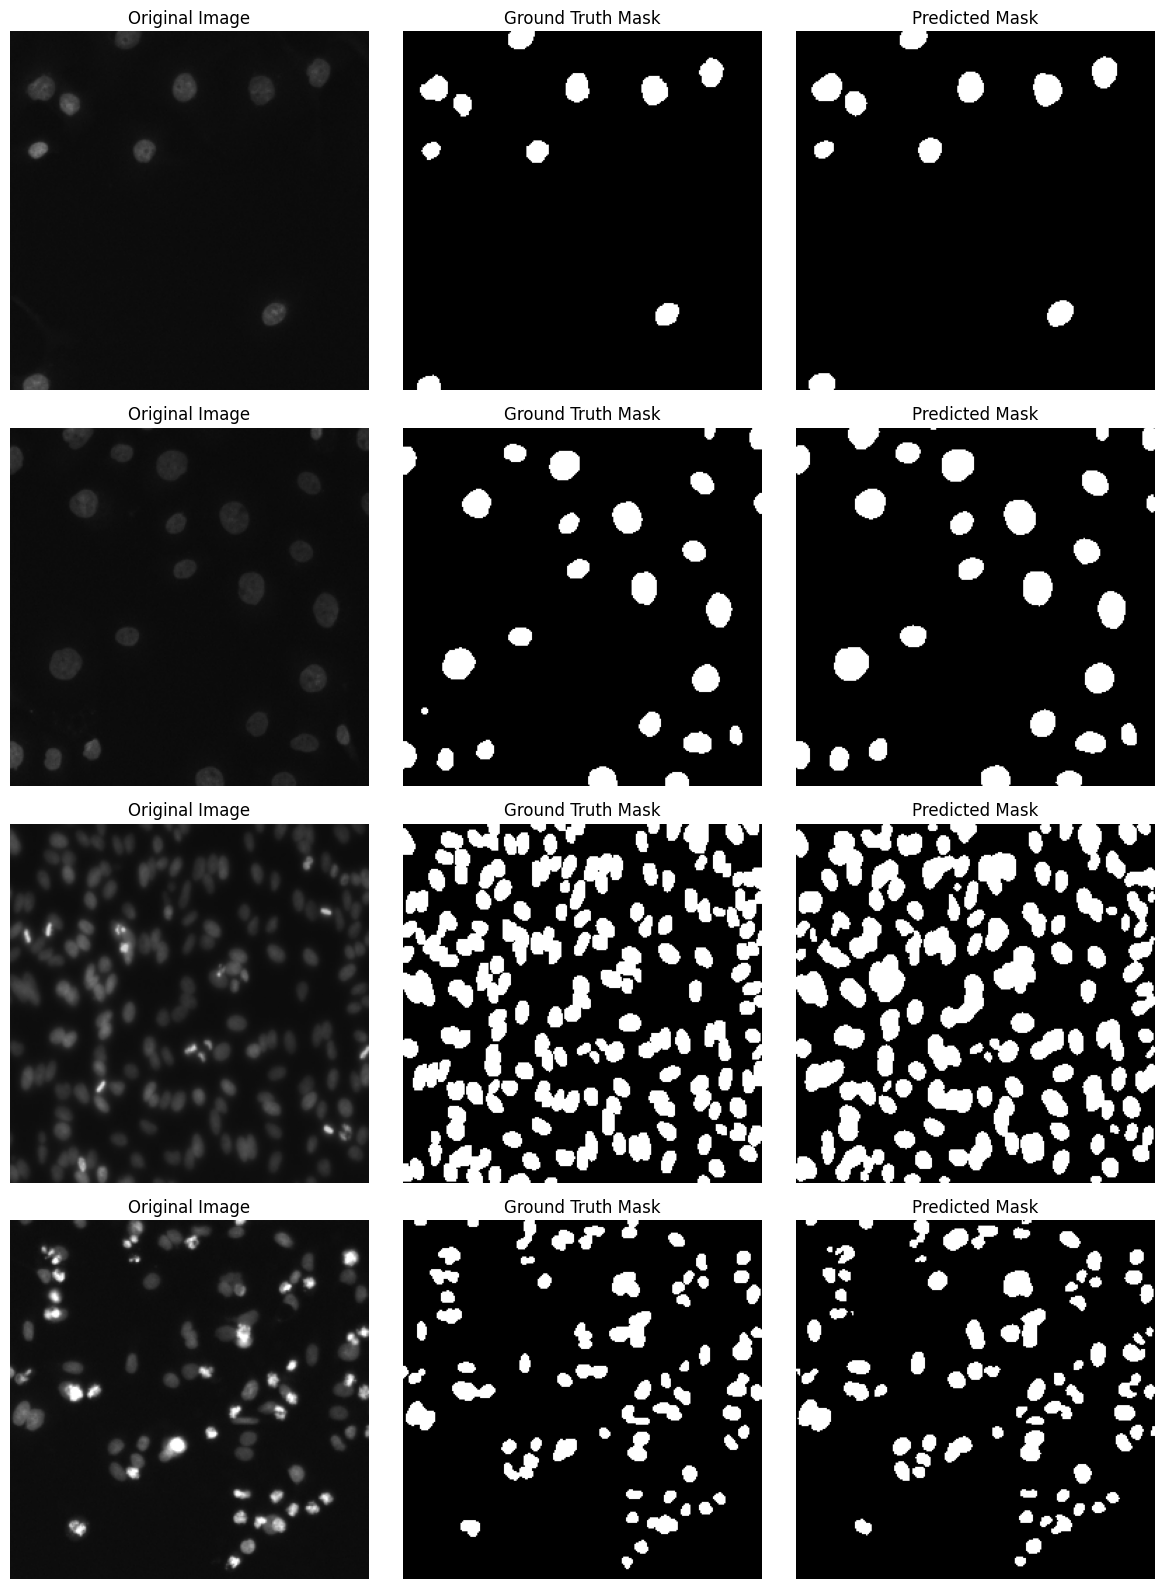

In [ ]:
model.eval()

images, masks = next(iter(test_loader))

images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    outputs = model(images)
    probs = torch.sigmoid(outputs)
    preds = (probs > 0.5).float()

images = images.cpu()
masks = masks.cpu()
preds = preds.cpu()

num_examples = 4

plt.figure(figsize=(12, 4 * num_examples))

for i in range(num_examples):
    plt.subplot(num_examples, 3, i * 3 + 1)
    plt.imshow(images[i].permute(1, 2, 0))
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(num_examples, 3, i * 3 + 2)
    plt.imshow(masks[i].squeeze(), cmap="gray")
    plt.title("Ground Truth Mask")
    plt.axis("off")

    plt.subplot(num_examples, 3, i * 3 + 3)
    plt.imshow(preds[i].squeeze(), cmap="gray")
    plt.title("Predicted Mask")
    plt.axis("off")

plt.tight_layout()
plt.show()